# 1. From an area to a network

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/01_area_to_network.ipynb) <a href="https://khoshkhah.github.io/duckOSM/notebooks/01_area_to_network.ipynb" download><img src="https://img.shields.io/badge/Download-notebook-F37626?logo=jupyter&logoColor=white" alt="Download the notebook"></a>

You get the network of an area, look at its modes, draw it and query it.

| Step | Call |
|---|---|
| Get and build an area | `duckosm.network`, or `duckosm.AreaPicker` and `area.build` |
| See what is in the file | `net`, `net.summary()`, `net.columns()` |
| Draw the network | `net.map()`, `net.walking.map()` |
| Query the edges | `net.driving.edges()`, `net.sql()` |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
# Until duckOSM 0.9.0 is on PyPI, the SDK of these notebooks is in the nightly wheel of main (the GitHub pre-release "nightly").
import importlib.util, json, urllib.request
def nightly_wheel():       # the address of the newest nightly wheel
    release = json.load(urllib.request.urlopen("https://api.github.com/repos/Khoshkhah/duckOSM/releases/tags/nightly"))
    return next(a["browser_download_url"] for a in release["assets"] if a["name"].endswith(".whl"))
if importlib.util.find_spec("duckosm") is None:      # not installed: install it with the extras of this notebook
    %pip install -q "duckosm[widget,viz] @ {nightly_wheel()}"
import duckosm             # the SDK
if not hasattr(duckosm, "network"):                    # an old duckOSM (0.8.0 or older), without the SDK
    %pip install -q --force-reinstall --no-deps "duckosm @ {nightly_wheel()}"
    raise SystemExit("duckOSM is updated: restart the session (in Colab: Runtime > Restart session), then run this cell again")
print("duckosm", duckosm.__version__)    # the version

duckosm 0.8.0


## Quick start

One call gets the OSM file of Monaco and builds two modes, driving and walking. The area is the city of Monaco, OSM
relation 2220322 (2.4 km² of land). The name "Monaco" finds the country, whose boundary includes the sea. Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

In [2]:
net = duckosm.network(osm_id=2220322, modes=["driving", "walking"], name="monaco")    # get and build Monaco: a duckosm.Network
net                                                               # the card: the file, and the edges, nodes and km of each mode

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0


In [3]:
net.summary()    # one row for each mode

,mode,edges,nodes,km,oneway_km
0,driving,2840,1768,96.2,35.5
1,walking,11938,4589,260.6,0.0


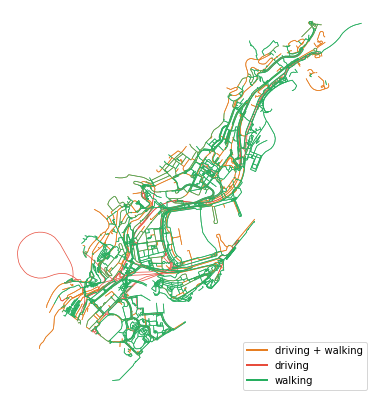

In [4]:
net.map()    # all modes on one map

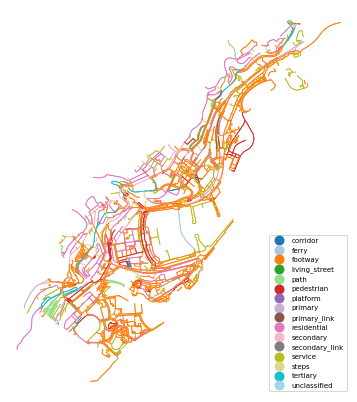

In [5]:
net.walking.map()    # only the walking network: net.walking is the view of one mode

## Choose the area on a map

The widget shows a map. Choose an area with one of the tabs (Search, OSM id, Box, H3 cell, File), then click **Get**. The line under the map shows the Geofabrik extract and its size before the download.

If you do not choose an area, the notebook uses Monaco. The guide is [Choose an area in Jupyter](https://khoshkhah.github.io/duckOSM/guides/area-picker/).

![The AreaPicker widget: the OSM id 2220322 gives the city of Monaco](https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/area-picker.png)

In [6]:
picker = duckosm.AreaPicker(out="data")              # the files go into the folder data/
picker.area = {"mode": "osm_id", "osm_id": 2220322}   # the area when you choose none on the map
picker                                               # the map

`picker.get()` downloads the extract (when it is not in the cache) and cuts it to the boundary. If you clicked **Get**, the cell waits for that run.

In [7]:
area = picker.result or picker.get()    # the result of Get, or get it now
area                                    # the card: the OSM file and the boundary

boundary: Monaco, OSM relation 2220322, 2.39 km², from Nominatim

,file,size
OSM file,data/monaco.osm.pbf,0.6 MB
boundary,data/monaco.geojson,16 kB


In [8]:
net = area.build(modes=["driving", "walking"])    # build the network of the area
net                                               # the card of the new network

Output: data/monaco.duckdb

mode,edges,nodes,km,oneway_km
driving,2840,1768,96.2,35.5
walking,11938,4589,260.6,0.0


## Your own PBF file, and the build options

`pbf=` takes an `.osm.pbf` file of your own. Without `boundary=`, the whole file is the area; with it, the build cuts
the file to the boundary. Here the file is a Monaco extract (0.6 MB), and the boundary is a box around Monte Carlo,
written as a GeoJSON file.

The build options are keywords: `speeds`, `costs`, `restrictions`, `bus_routes`, `connect_paths`, `snap_m` and `dem`.
`config=` gives every other key of the config file, as a YAML or JSON file or as a dict; a keyword wins over the
config. The table is on the [Python SDK page](../reference/python.md#build-options).

In [9]:
import urllib.request                                                           # your own file: here, a download
mine = "data/my_monaco.osm.pbf"
urllib.request.urlretrieve("https://github.com/Khoshkhah/duckOSM/raw/main/tests/data/monaco.osm.pbf", mine)
own = duckosm.network(pbf=mine, name="monaco_whole", modes=["driving"])          # the whole file, no boundary
own.summary()

Output: data/monaco_whole.duckdb

,mode,edges,nodes,km,oneway_km
0,driving,2844,1769,96.2,35.6


In [10]:
import json                                                                       # a boundary: a GeoJSON polygon
w, s, e, n = 7.418, 43.735, 7.432, 43.745                                         # a box around Monte Carlo
box = {"type": "Polygon", "coordinates": [[[w, s], [e, s], [e, n], [w, n], [w, s]]]}
json.dump({"type": "Feature", "properties": {"name": "monte_carlo"}, "geometry": box}, open("data/monte_carlo.geojson", "w"))
cut = duckosm.network(pbf=mine, boundary="data/monte_carlo.geojson", name="monte_carlo", modes=["driving"],
                      bus_routes=False, config={"clip": {"connect_snap_m": 5}})  # cut to the box, two options
cut.summary()                                                                     # only the roads in the box

Output: data/monte_carlo.duckdb

,mode,edges,nodes,km,oneway_km
0,driving,972,613,36.0,13.0


## Query the edges

Each row of `<mode>.edges` is one direction of a road. `edge_id` is a `BIGINT` content hash: it stays the same after a rebuild, a cut and an export. Other data joins on it (see notebook 5).

In [11]:
net.columns("driving.edges").head(8)    # the first columns of the table driving.edges and their types

,column_name,column_type,description
0,edge_id,BIGINT,
1,edge_ref,VARCHAR,
2,source,BIGINT,
3,target,BIGINT,
4,osm_id,BIGINT,
5,highway,VARCHAR,
6,name,VARCHAR,
7,oneway,BOOLEAN,


In [12]:
edges = net.driving.edges()                                              # the driving edges as a GeoDataFrame
edges[["edge_id", "name", "highway", "length_m", "maxspeed_kmh"]].head()    # five rows

,edge_id,name,highway,length_m,maxspeed_kmh
0,414242052250797,Boulevard du Ténao,residential,44.240875,30.0
1,2214154189574909,None,service,24.298845,20.0
2,15757195119014288,Rue du Ténao,residential,9.057960,30.0
3,16871577064511426,None,residential,3.996883,30.0
4,21502429769987032,None,residential,3.554246,30.0


In [13]:
net.sql("""SELECT highway, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km
           FROM driving.edges GROUP BY highway ORDER BY km DESC LIMIT 8""")    # the road classes, by length

,highway,edges,km
0,residential,919,31.7
1,service,855,23.7
2,secondary,429,14.9
3,tertiary,387,12.5
4,primary,197,11.2
5,primary_link,21,1.1
6,unclassified,13,0.6
7,secondary_link,13,0.4


In [14]:
net.sql("""SELECT name, round(sum(length_m)) AS length_m, count(*) AS edges, any_value(typeof(edge_id)) AS edge_id_type
           FROM driving.edges WHERE name IS NOT NULL GROUP BY name ORDER BY length_m DESC LIMIT 5""")    # the longest named roads

,name,length_m,edges,edge_id_type
0,Boulevard du Larvotto,5305.0,85,BIGINT
1,Boulevard du Jardin Exotique,3280.0,73,BIGINT
2,Avenue Princesse Grace,2576.0,86,BIGINT
3,Avenue Pasteur,2246.0,42,BIGINT
4,Tunnel Albert II,1994.0,7,BIGINT


## Draw the network

`show` sets how the notebook shows a map. The setting `DUCKOSM_MAP_SHOW` gives the default for all maps.

| `show` | The output | Size (Monaco) |
|---|---|---|
| `"live"` (default) | The live roadstyle map: zoom, click a road | about 6 MB |
| `"link"` | The live map saved as an HTML file in `maps/`, and a link to it | a link |
| `"picture"` | A PNG of the live roadstyle map, taken in headless Chromium | about 175 KB |
| `"plot"` | A matplotlib picture, without roadstyle | small |

`"picture"` needs Playwright: `pip install playwright` and `playwright install chromium`.

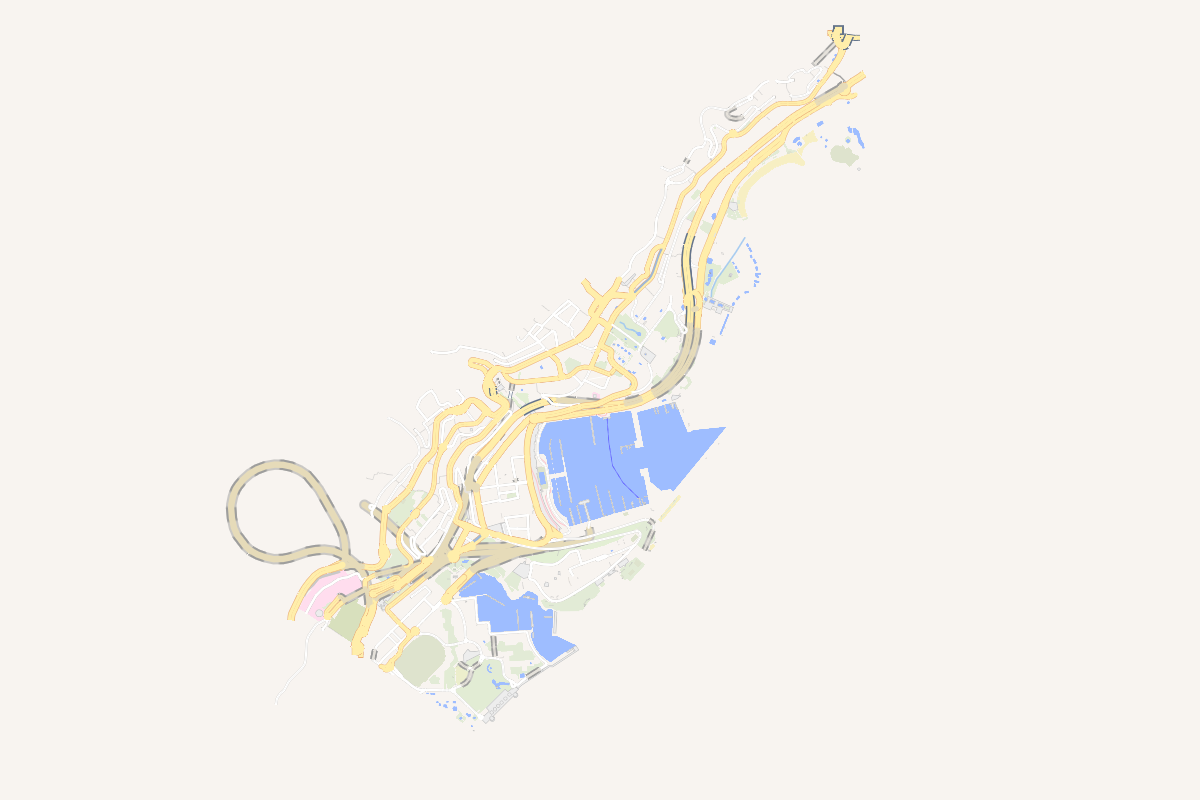

In [15]:
net.map(show="picture")    # a PNG of the live roadstyle map

In [16]:
net.map(show="link")    # the live map as an HTML file, and a link to open it

MapLink('maps/monaco-2.html')

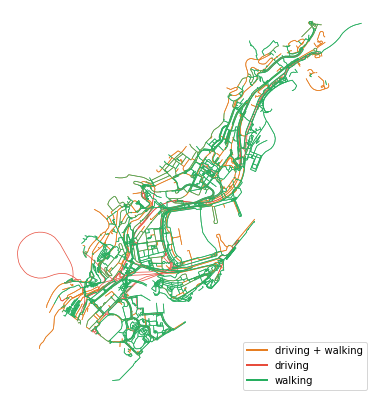

In [17]:
net.map(show="plot")    # matplotlib: the same as net.plot()

### The layers of the base map

`layers` sets the base map under the roads: `True` (all layers), `False` (the roads only) or a list of roadstyle
layer names. The default: all layers on the live map, the roads only with `plot`. `plot` draws `ocean`, `landcover`,
`water`, `waterways` and `buildings`.

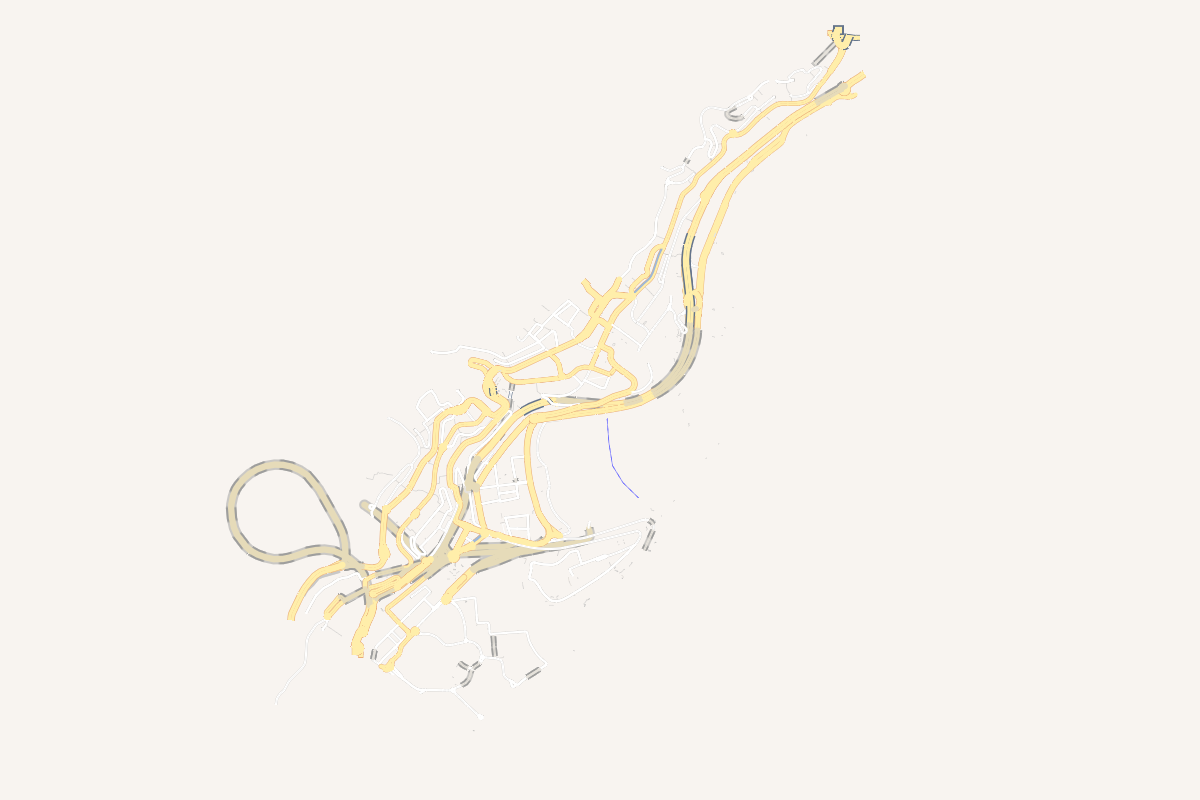

In [18]:
net.map(layers=False, show="picture")    # the roads only

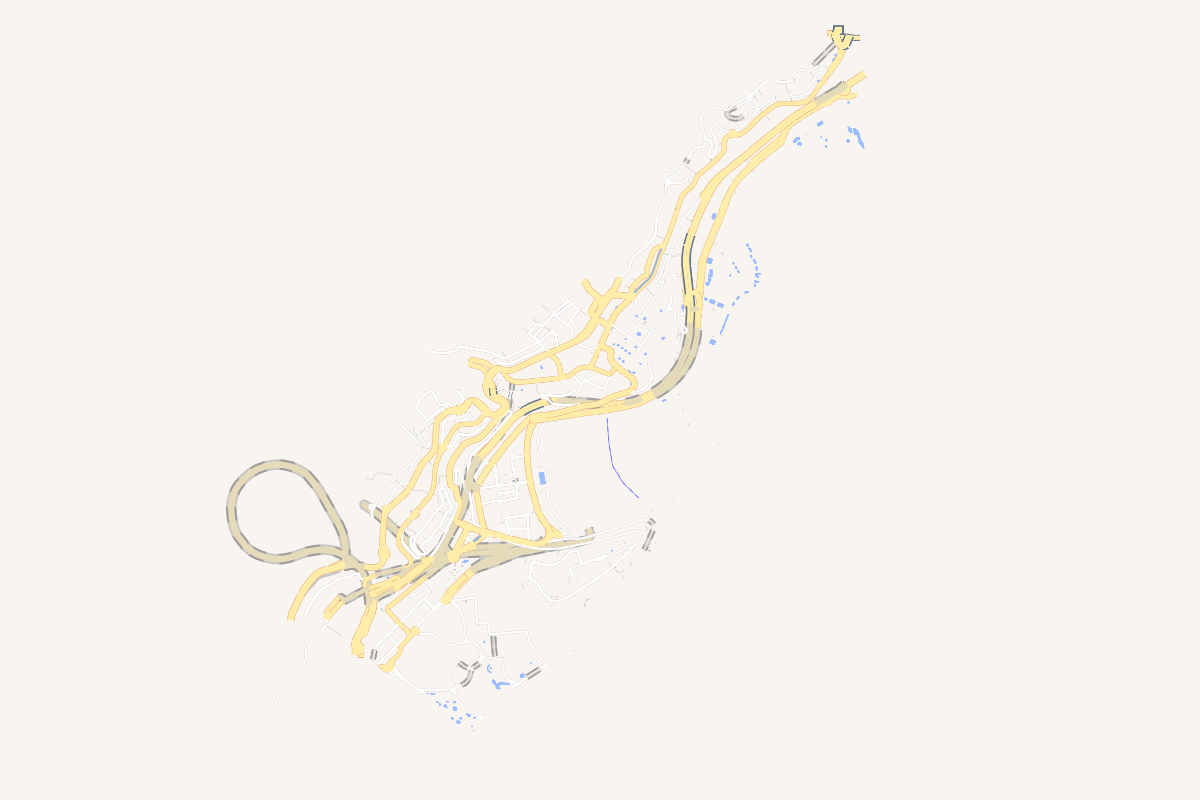

In [19]:
net.map(layers=["water", "buildings"], show="picture")    # the roads, the water and the buildings

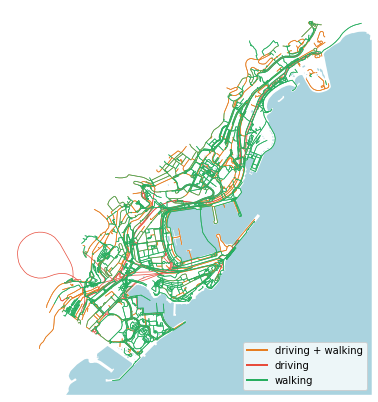

In [20]:
net.plot(layers=["ocean", "water"])    # matplotlib, with the sea and the water

### Roads of more than one mode

Many roads are in more than one mode: a street is a driving, a walking and a cycling road. A map of all modes gives each
road one color for the set of modes that can use it, with the colors of the "Modes" option of `net.dashboard()`:

| Modes | Color |
|---|---|
| all modes | gray |
| driving + walking | orange |
| driving + cycling | purple |
| walking + cycling | teal |
| driving | red |
| walking | green |
| cycling | blue |

cut: 34461 nodes, 5685 ways, 339 relations

Output: data/monaco.duckdb

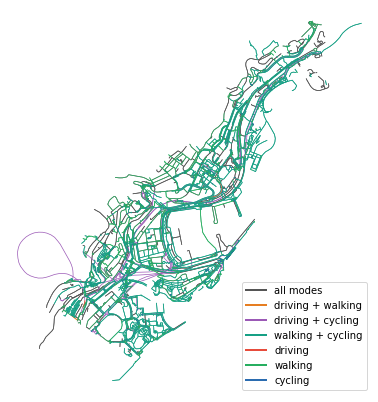

In [21]:
net3 = duckosm.network(osm_id=2220322, modes=["driving", "walking", "cycling"], name="monaco")    # Monaco with three modes
net3.plot()    # the roads only, one color for each set of modes